In [2]:
import specpolFlow as pol
import matplotlib.pyplot as plt
import VPtools as vp
import numpy as np
from pathlib import Path
import math
from matplotlib.gridspec import GridSpec
path_google = 'G:/Shared drives/'
obs_folder = Path(r"G:\Shared drives\BinamicsOstars\DataFromEve\spectra_tovero")
# import normPlot
import pandas as pd


In [3]:
hd = "hd191201"    

obs = sorted([f.name for f in obs_folder.glob(f"{hd}*.s")])

print(f"Found {len(obs)} observations for {hd}:")
for f in obs:
    print(f)
print(obs)

filename1 = obs[0]
filename2 = obs[1]

spec1 = pol.read_spectrum(obs_folder / filename1)
spec1 = spec1.merge_orders(mode="trim")
# spec2 = pol.read_spectrum(obs_folder / filename2)
# spec2 = spec2.merge_orders(mode="trim")

label1 = filename1.replace("_rn.s", "")
# label2 = filename2.replace("_rn.s", "")
spec = spec1
name = filename1

Found 2 observations for hd191201:
hd191201_E_1308737pn_rn.s
hd191201_E_1720107pnm_rn.s
['hd191201_E_1308737pn_rn.s', 'hd191201_E_1720107pnm_rn.s']


Make LSD line profiles

Modified line mask, removed 153 too closely spaced lines
Average observed spec velocity spacing: 1.806632 km/s
using a 87 point profile with 7.000000 km/s pixels
mean mask depth 0.081543 wl 498.864 Lande 1.171177 (from 1024 lines)
mean mask norm weightI 0.407715 weightV 0.382674
saving model spectrum to  ...
I reduced chi2 314.6670 (chi2 36787086.34 constraints 116995 dof 87)
 Rescaling error bars by: 17.738855
V reduced chi2 1.2037 (chi2 140719.22 constraints 116995 dof 87)
 Rescaling error bars by: 1.097121
 removing profile continuum pol: -4.3375e-06 +/- 2.3730e-09 (avg err 4.8615e-05)
N1 reduced chi2 1.2116 (chi2 141651.29 constraints 116995 dof 87)
 Rescaling error bars by: 1.100749
 removing profile continuum pol: -5.4516e-06 +/- 2.3888e-09 (avg err 4.8776e-05)
(possible Stokes I uncertainty underestimate 2.7159e-03 vs 7.9441e-04)
line range estimate 182 182 km/s
V in line reduced chi^2      nan (chi2   0.000000) 
 detect prob    nan (fap          nan)
 Non-detection V (fap      

c:\Users\alex\Documents\GitHub\BStarMiMeS\.venv\Lib\site-packages\LSDpy\lsdpFunc.py:735: RuntimeWarning: invalid value encountered in scalar divide
  chi2Vin/approxDOFin, chi2Vin, probVIn, 1.-probVIn))
c:\Users\alex\Documents\GitHub\BStarMiMeS\.venv\Lib\site-packages\LSDpy\lsdpFunc.py:746: RuntimeWarning: invalid value encountered in scalar divide
  chi2N1in/approxDOFin, chi2N1in, probN1In, 1.-probN1In))


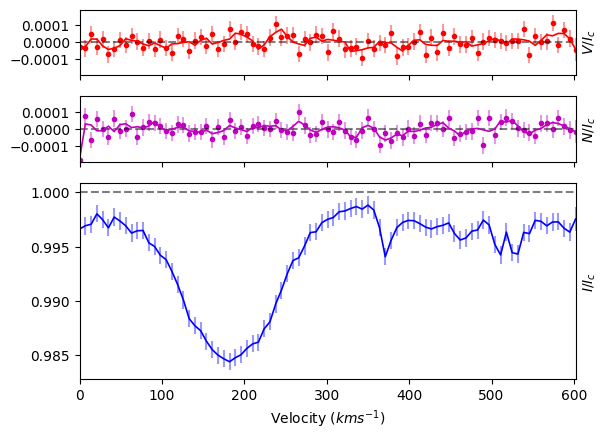

,V bz (G),V bz sig (G),V FAP,N1 bz (G),N1 bz sig (G),N1 FAP,N2 bz (G),N2 bz sig (G),N2 FAP,norm_method,norm,cog_method,cog,int. range start,int. range end
vp7,-74.551,55.316,0.742,-36.637,55.491,0.981,0.0,0.0,0.0,1.0,1.0,I,189.736,100,300


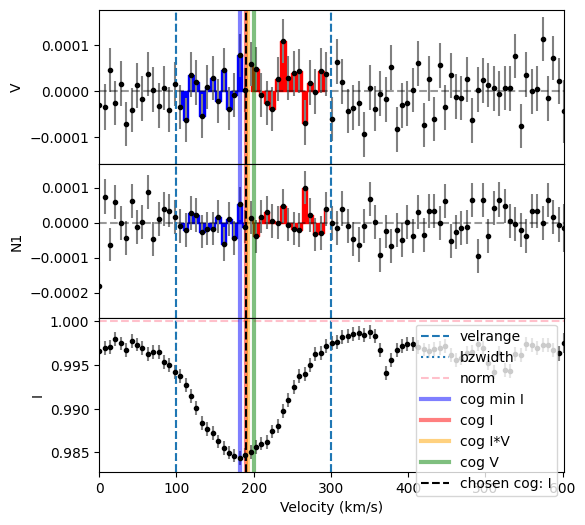

In [ ]:
# Calculate LSD 
# but with run_lsdpy with one feature at a time
mask_clean='T30000G375_depth0.01_clean.mask' #path of the cleaned mask
sfile = obs_folder/filename1

LSD_outfile = 'lsdoutputsHD191201_1308737/hd191201_E_1308737pn_vp7_Right_0_600.lsd'
lsd, mod = pol.run_lsdpy(obs = sfile, mask = mask_clean, outLSDName = LSD_outfile, 
           velStart = 0, velEnd = 600, velPixel =7,  # number of points / vsini
           normDepth = 0.2, normLande = 1.2, normWave = 500.0)

velPixels = [7]
lsd_folder = Path('lsdoutputsHD191201_1308737')
output_folder = Path('lsdoutputsHD191201_1308737')
Bz_results_left = {}

for velPixel in velPixels:
    label = 'default' if velPixel is None else f'vp{velPixel}'
    LSD_outfile = lsd_folder/'hd191201_E_1308737pn_vp7_Left_0_600.lsd'
    lsd = pol.read_lsd(str(LSD_outfile))

    # left component velocity range: [-300,-100], bzwidth=80
    # right component velocity range: [90,280], bzwidth=100
    Bz, fig = lsd.calc_bz(cog='I', norm=1.0, velrange=[-280,120],
                          lambda0=500.0, geff=1.2, plot=True, figsize=(6,6))

    result = (f"Bz = {Bz['V bz (G)']:.1f} ± {Bz['V bz sig (G)']:.1f} G\n"
              f"V FAP = {Bz['V FAP']:.3g}\n"
              f"Null Bz = {Bz['N1 bz (G)']:.1f} ± {Bz['N1 bz sig (G)']:.1f} G\n"
              f"Null FAP = {Bz['N1 FAP']:.3g}")

    Bz_results_left[label] = Bz

df = pd.DataFrame.from_dict(Bz_results_left, orient='index')
display(df.round(3))

,V bz (G),V bz sig (G),V FAP,N1 bz (G),N1 bz sig (G),N1 FAP,N2 bz (G),N2 bz sig (G),N2 FAP,norm_method,norm,cog_method,cog,int. range start,int. range end
vp7,9.957,64.368,0.435,9.816,64.54,0.751,0.0,0.0,0.0,1.0,1.0,I,-212.303,-280,-120


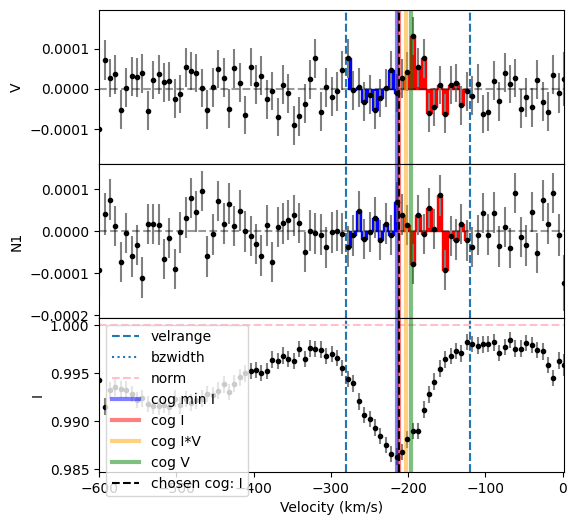

In [21]:
lsd_folder = Path('lsdoutputsHD191201_1308737')
output_folder = Path('lsdoutputsHD191201_1308737')
Bz_results_left = {}
velPixels = [7]

for velPixel in velPixels:
    label = 'default' if velPixel is None else f'vp{velPixel}'
    LSD_outfile = 'lsdoutputsHD191201_1308737/hd191201_E_1308737pn_vp7_Left-600_0.lsd'
    lsd = pol.read_lsd(str(LSD_outfile))

    # left component velocity range: [-300,-100], bzwidth=80
    # right component velocity range: [90,280], bzwidth=100
    Bz, fig = lsd.calc_bz(cog='I', norm=1.0, velrange=[-280,-120],
                          lambda0=500.0, geff=1.2, plot=True, figsize=(6,6))

    result = (f"Bz = {Bz['V bz (G)']:.1f} ± {Bz['V bz sig (G)']:.1f} G\n"
              f"V FAP = {Bz['V FAP']:.3g}\n"
              f"Null Bz = {Bz['N1 bz (G)']:.1f} ± {Bz['N1 bz sig (G)']:.1f} G\n"
              f"Null FAP = {Bz['N1 FAP']:.3g}")

    Bz_results_left[label] = Bz

df = pd.DataFrame.from_dict(Bz_results_left, orient='index')
display(df.round(3))

In [ ]:
# manual calculation of LSD
lsd = pol.read_lsd('lsdoutputsHD191201_1308737/hd191201_E_1308737pn_vp7_Left-600_0.lsd')
vel = lsd.vel
specI = lsd.specI
specV = lsd.specV
vc = -210 # km/s
mask=(vel>=-280)&(vel<=-120)
v_minus_vc = vel[mask]-vc
integrand_numerator = v_minus_vc*specV[mask]
numerator = np.trapezoid(integrand_numerator, vel[mask])

integrand_denominator = 1.-specI[mask]
denominator = np.trapezoid(integrand_denominator, vel[mask])
lambda0 = 500.0 #nm
geff = 1.2
c=299792.458 # km/s
bz = -2.14e11/(lambda0*geff*c)*numerator/denominator
print(bz)


11.462287004698188


In [ ]:
# Do LSD stuff 

Modified line mask, removed 153 too closely spaced lines
Average observed spec velocity spacing: 1.806632 km/s
using a 87 point profile with 7.000000 km/s pixels
mean mask depth 0.081543 wl 498.864 Lande 1.171177 (from 1024 lines)
mean mask norm weightI 0.407715 weightV 0.382674
saving model spectrum to  ...
I reduced chi2 360.6784 (chi2 42041038.51 constraints 116648 dof 87)
 Rescaling error bars by: 18.991536
V reduced chi2 1.2074 (chi2 140738.74 constraints 116648 dof 87)
 Rescaling error bars by: 1.098829
 removing profile continuum pol: -5.8140e-06 +/- 2.3714e-09 (avg err 4.8605e-05)
N1 reduced chi2 1.2139 (chi2 141491.96 constraints 116648 dof 87)
 Rescaling error bars by: 1.101766
 removing profile continuum pol: -6.5417e-06 +/- 2.3841e-09 (avg err 4.8735e-05)
(possible Stokes I uncertainty underestimate 2.6615e-03 vs 8.5672e-04)
ERROR: could not find line range!  (using full profile)
V in line reduced chi^2 0.777928 (chi2  63.790090) 
 detect prob 0.068077 (fap 9.319227e-01)
 N

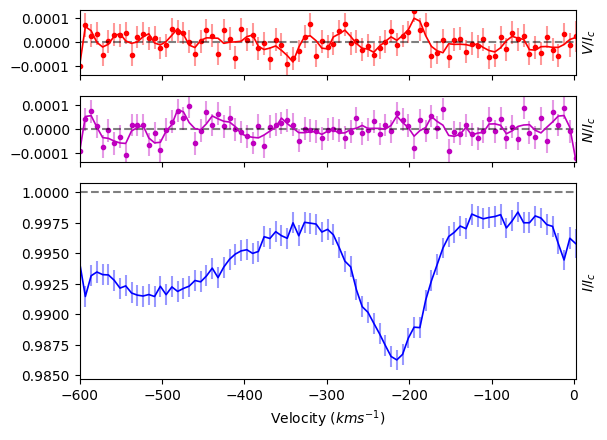

In [5]:
velPixels = [7]
lsd_folder = Path('lsdoutputsHD191201_1308737')
lsd_folder.mkdir(exist_ok=True)
Bz_results = {}

for velPixel in velPixels:
    label = 'default' if velPixel is None else f'vp{velPixel}'
    LSD_outfile = lsd_folder / f'hd191201_E_1308737pn_{label}.lsd'
    kwargs = {} if velPixel is None else {'velPixel': velPixel}

    lsd, mod = pol.run_lsdpy(obs=sfile, mask=mask_clean, outLSDName=str(LSD_outfile),
                            velStart=-600, velEnd=0, normDepth=0.2, normLande=1.2, normWave=500.0,
                            plotLSD=True, outPlotLSDName=str(lsd_folder / f'hd191201_E_1308737pn_{label}_LSD.pdf'),
                            **kwargs)
    lsd.save(LSD_outfile)


default: Bz = {'V bz (G)': np.float64(-23.120463377410378), 'V bz sig (G)': np.float64(107.17322054716409), 'V FAP': np.float64(0.38927624972577557), 'N1 bz (G)': np.float64(-106.09563841674797), 'N1 bz sig (G)': np.float64(107.48646565749635), 'N1 FAP': np.float64(0.8722695381805022), 'N2 bz (G)': 0.0, 'N2 bz sig (G)': 0.0, 'N2 FAP': 0.0, 'norm_method': 'auto', 'norm': np.float64(0.9973879), 'cog_method': 'I', 'cog': np.float64(-230.74003101284353), 'int. range start': np.float64(-310.74003101284353), 'int. range end': np.float64(-150.74003101284353)}
vp1: Bz = {'V bz (G)': np.float64(-31.540558427104337), 'V bz sig (G)': np.float64(114.56829839815514), 'V FAP': np.float64(0.20133760981309756), 'N1 bz (G)': np.float64(-85.74127536634784), 'N1 bz sig (G)': np.float64(114.87615358275296), 'N1 FAP': np.float64(0.3427005197562293), 'N2 bz (G)': 0.0, 'N2 bz sig (G)': 0.0, 'N2 FAP': 0.0, 'norm_method': 'auto', 'norm': np.float64(0.9973180500000001), 'cog_method': 'I', 'cog': np.float64(-231

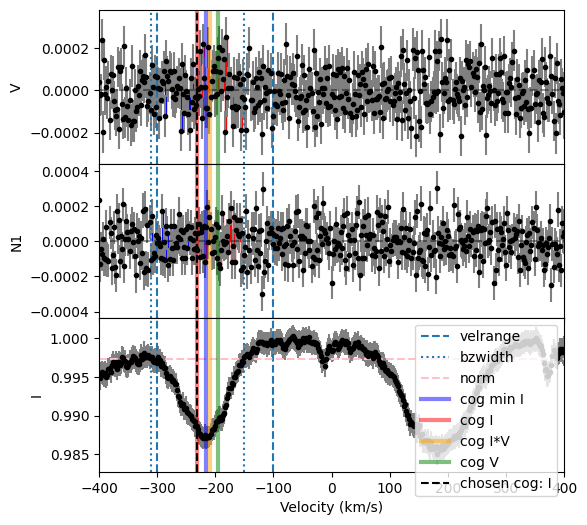

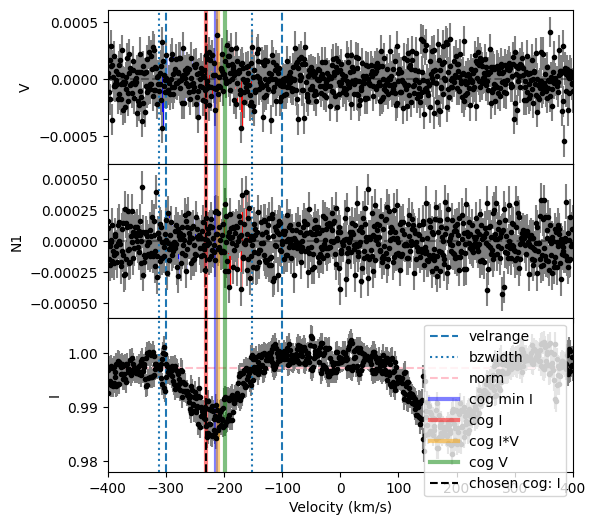

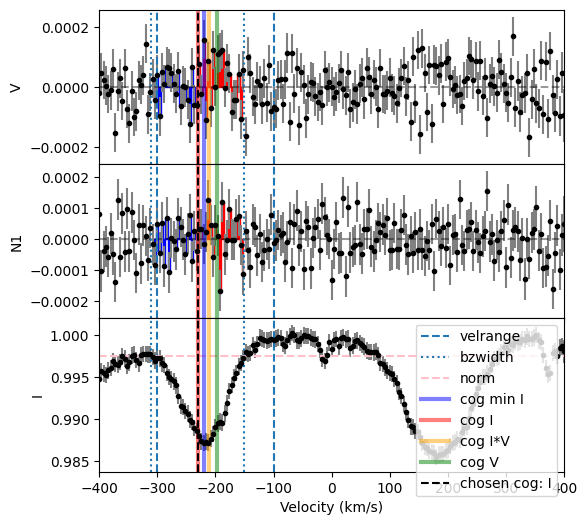

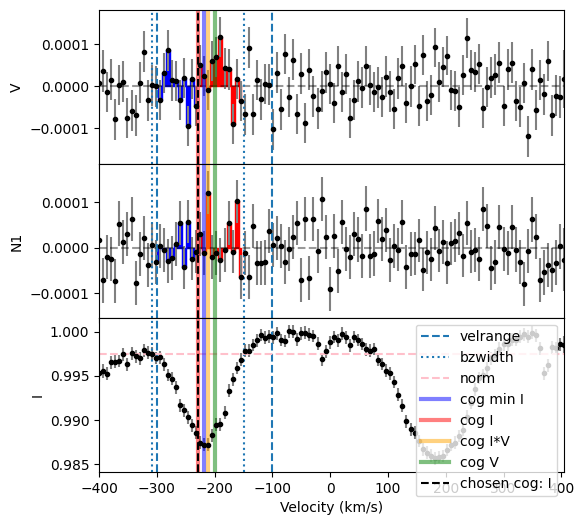

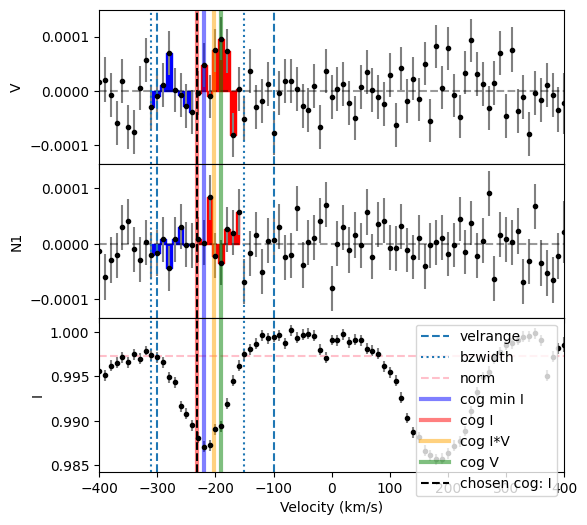

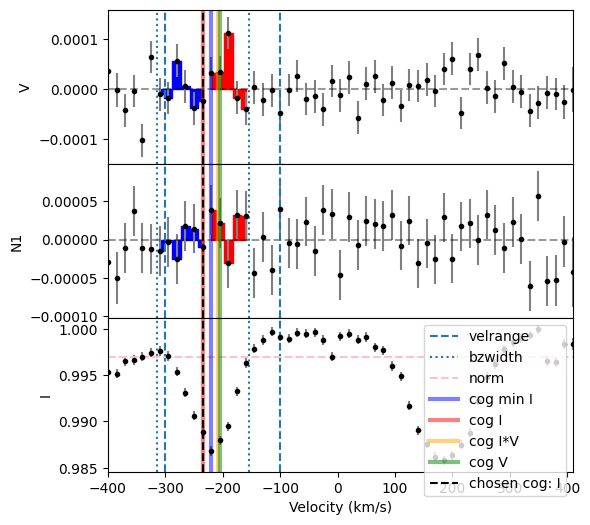

In [ ]:
velPixels = [None, 1, 4, 7, 10, 15]
lsd_folder = Path('lsdoutputsHD191201/lsdprofiles_changingVelPixel')
output_folder = Path('lsdoutputsHD191201/bz_normauto')
Bz_results_left = {}

for velPixel in velPixels:
    label = 'default' if velPixel is None else f'vp{velPixel}'
    LSD_outfile = lsd_folder / f'hd191201_E_1308737pn_{label}.lsd'
    lsd = pol.read_lsd(str(LSD_outfile))

    # left component velocity range: [-300,-100], bzwidth=80
    # right component velocity range: [90,280], bzwidth=100
    Bz, fig = lsd.calc_bz(cog='I', norm='auto', velrange=[-300,-100], bzwidth=80,
                          lambda0=500.0, geff=1.2, plot=True, figsize=(6,6))

    result = (f"Bz = {Bz['V bz (G)']:.1f} ± {Bz['V bz sig (G)']:.1f} G\n"
              f"V FAP = {Bz['V FAP']:.3g}\n"
              f"Null Bz = {Bz['N1 bz (G)']:.1f} ± {Bz['N1 bz sig (G)']:.1f} G\n"
              f"Null FAP = {Bz['N1 FAP']:.3g}")

    Bz_results_left[label] = Bz

    print(f'{label}: Bz = {Bz}')

In [18]:
df = pd.DataFrame.from_dict(Bz_results_right, orient='index')
print('bz results for right component with different vp')
display(df.round(3))

bz results for right component with different vp


,V bz (G),V bz sig (G),V FAP,N1 bz (G),N1 bz sig (G),N1 FAP,N2 bz (G),N2 bz sig (G),N2 FAP,norm_method,norm,cog_method,cog,int. range start,int. range end
default,-74.427,86.540,0.116,-23.352,86.747,0.396,0.0,0.0,0.0,auto,0.998,I,183.836,83.836,283.836
vp1,-65.396,91.131,0.189,-3.368,91.345,0.176,0.0,0.0,0.0,auto,0.998,I,183.613,83.613,283.613
vp4,-80.788,85.573,0.348,-31.459,85.780,0.988,0.0,0.0,0.0,auto,0.998,I,184.034,84.034,284.034
vp7,-70.532,76.711,0.586,-51.282,76.895,0.987,0.0,0.0,0.0,auto,0.998,I,183.767,83.767,283.767
vp10,-63.349,76.992,0.197,-50.145,77.182,0.821,0.0,0.0,0.0,auto,0.998,I,183.854,83.854,283.854
vp15,-73.504,71.069,0.338,-47.623,71.229,0.910,0.0,0.0,0.0,auto,0.998,I,184.774,84.774,284.774
